<h2>
En este colab se realizara el antrenamiento del modelo para la deteccion de anomalias en los precios, para que a la hora de hacer scraping en las tiendas web de los supermercados, estos datos pasen por un filtro que analise si los precios son razonables o no.
</h2>

Instalamos librerias

In [2]:
!rm -rf /content/SEPA_Dataset /content/drive

In [3]:
!rm -rf /content/drive

In [4]:
from google.colab import drive
drive.flush_and_unmount()

# Forzamos la eliminación de la carpeta residual
!rm -rf /content/drive

Drive not mounted, so nothing to flush and unmount.


In [5]:
!pip install -q --upgrade gdown

Descargamos los archivos .zip con los dataset

In [6]:
!gdown --folder "https://drive.google.com/drive/folders/16qcU9GKlwKfpr1TsvospxIr6N9FdqhAV?usp=sharing" -O /content/SEPA_Dataset

Retrieving folder contents
Processing file 1cxGSdnTimZJIVdTj2_A5lnBGp5HIatC8 sepa_1_comercio-sepa-12_2026-11-05_09-05-11.zip
Processing file 13y-weoztdxiVKVGhM-dr01zguCKI0_Ag sepa_1_comercio-sepa-12_2026-11-06_09-05-10.zip
Processing file 1SrSCkKC16sPecO5b7EgkmP_OulXH8SgS sepa_1_comercio-sepa-12_2026-11-07_09-05-10.zip
Processing file 1fXrhLSZHY4vl0QpBg9CWirJ7NkKkxWaT sepa_1_comercio-sepa-12_2026-11-08_09-05-10.zip
Processing file 1dhPsR_16nGfAoVnslCrX5RRx-lYC4Kto sepa_1_comercio-sepa-12_2026-11-09_09-05-10.zip
Processing file 1yQubbXc9bvUVZEmv37iKO4fQpIsm_bIT sepa_1_comercio-sepa-12_2026-11-10_09-05-10.zip
Processing file 11TgguJGZpdI1R-wjV1CBRZnFWZzWHO_o sepa_1_comercio-sepa-12_2026-11-11_09-05-11.zip
Processing file 1_7kmfdlHQOe0WSoOvOv8LefYDWFSbY7q sepa_1_comercio-sepa-13_2026-11-05_09-05-11.zip
Processing file 1IdDQMprWjf3Vyjf7wVMg7zgwSsp99-kj sepa_1_comercio-sepa-13_2026-11-06_09-05-10.zip
Processing file 13RLJ5YgGGSQt1IntInwy-PXZhpdMTnw1 sepa_1_comercio-sepa-13_2026-11-08_09-05-

In [ ]:
import zipfile
import os

ruta_zips = '/content/SEPA_Dataset/*.zip'
os.makedirs('/content/SEPA_Dataset', exist_ok=True)
print("¡Descomprimido con éxito!")

# 1. Obtencion de los Dataset y creacion de Dataframe

In [8]:
import glob
import os
import zipfile
import pandas as pd

ruta_zips = '/content/SEPA_Dataset/*.zip'
archivos = sorted(glob.glob(ruta_zips))

# Código ISO de provincia en SEPA:
PROVINCIA_OBJETIVO = 'AR-B'   # 'AR-B' = Buenos Aires | 'AR-C' = CABA

lista_dfs = []
# Columnas que nos interesan de lo productos
columnas_utiles = [
    'id_sucursal',
    'id_producto',
    'productos_descripcion',
    'productos_marca',
    'productos_precio_lista',
    'productos_precio_referencia',
    'productos_precio_unitario_promo1',
]


for ruta in archivos:
  # Obtenemos el nombre del archivo
  nombre_archivo = os.path.basename(ruta)

  # Extraer fecha del nombre del archivo
  try:
    fecha = nombre_archivo.split('_')[3]
  except IndexError:
    fecha = 'desconocida'

  # Abrimos el archivo .zip
  with zipfile.ZipFile(ruta, 'r') as z:
    # Obtenemos el nombre del Supermercado, a traves del archivo 'comercio.csv'
    df_comercio = pd.read_csv(z.open('comercio.csv'), sep='|')
    nombre_super = df_comercio['comercio_razon_social'].iloc[0]

    # Obtener solo los IDs de las sucursales en la provincia elegida, a traves del archivo 'sucursales.csv'
    df_suc = pd.read_csv(z.open('sucursales.csv'), sep='|', dtype=str)
    ids_validos = set(
        df_suc[
            df_suc['sucursales_provincia'].str.strip() == PROVINCIA_OBJETIVO
        ]['id_sucursal'].str.strip()
    )

    # Si no hay sucursales del supermercado en esta provincia continuamos al siguiente supermercado.
    if not ids_validos:
      print(f'Omitido: No hay supermercados {nombre_super} en {PROVINCIA_OBJETIVO}')
      continue

    # Obtenemos el df de los productos con las columnas de interes
    df_prod = pd.read_csv(
        z.open('productos.csv'),
        sep='|',                                          # Caracter que separa las columnas dentro del archivo .csv
        usecols=lambda c: c in columnas_utiles,           # Se toman las columnas seleccionadas y se ignoran las demas
        dtype={'id_sucursal': str, 'id_producto': str},   # Indicamos que 'id_sucursal' y 'id_producto' son tipo String
        low_memory=False,                                 # Evita que tome suposiciones de los tipos de datos antes de tiempo
    )
    df_prod['id_sucursal'] = df_prod['id_sucursal'].str.strip()         # Limpiamos posibles espacios al inicio o fin del String
    df_prod = df_prod[df_prod['id_sucursal'].isin(ids_validos)].copy()  # Filtramos los productos de las sucursales objetivo

    # A cada producto lo relacionamos con la fecha y el supermercado
    df_prod['fecha'] = fecha
    df_prod['supermercado'] = nombre_super

    # Guardamos el df en la lista
    lista_dfs.append(df_prod)
    print(f'Cargado: {fecha} | {nombre_super} ({len(df_prod)} filas)')


# Creamos un unico DF con la union de todos los DF de los dataset
df_crudo = pd.concat(lista_dfs, ignore_index=True)

print('\n--- RESUMEN FINAL ---')
print(f'Total de filas: {len(df_crudo)}')
print(df_crudo['supermercado'].value_counts())
df_crudo.head(100).to_csv('datos_crudos_SEPA_sample.csv', index=False)

Cargado: 2026-11-05 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (460322 filas)
Cargado: 2026-11-05 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (460322 filas)
Cargado: 2026-11-05 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (460322 filas)
Cargado: 2026-11-05 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (460322 filas)
Cargado: 2026-11-06 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (461537 filas)
Cargado: 2026-11-06 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (461537 filas)
Cargado: 2026-11-06 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (461537 filas)
Cargado: 2026-11-06 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (461537 filas)
Cargado: 2026-11-07 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (459638 filas)
Cargado: 2026-11-07 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (459638 filas)
Cargado: 2026-11-07 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (459638 filas)
Cargado: 2026-11-07 | COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A. (459638 filas)
Carg

In [9]:
display(df_crudo.head(10))

,id_sucursal,id_producto,productos_descripcion,productos_marca,productos_precio_lista,productos_precio_referencia,productos_precio_unitario_promo1,fecha,supermercado
0,235,7798370550296,PREMEZCLA P/CHIPA VEG.S/TACC NATURAL POP PAQ 2...,NATURAL POP,3237.00,16185.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
1,67,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
2,68,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
3,178,8445291738775,CAFÉ MEZCLA INST.MOL. NESCAFE GOLD FRA 95 GRM,NESCAFE GOLD,21970.00,231263.15,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
4,69,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
5,70,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
6,178,8445291830806,CAFÉ E/GRANO TOSTADO MEDIO NESCAFE GOLD PAQ 25...,NESCAFE GOLD,20964.00,83856.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
7,75,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5453.21,10906.42,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
8,65,7840127000124,YERBA MATE KURUPI MENTA Y BOLDO CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.
9,178,7790170949201,CAFÉ MOLIDO TOSTADO BRASIL LA VIRGINIA PAQ 250...,LA VIRGINIA,15659.00,62636.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.


# 2. ETL


## Limpieza de los datos

Aca Buscamos eliminar filas con valores vacios o reemplazarlos por otros, precios rotos, etc.

In [10]:
import numpy as np
# Limpieza basica: Eliminamos productos que no tengan precio o precios negativos
df_limpio = df_crudo.dropna(subset=['productos_precio_lista', 'id_producto']).copy()
df_limpio = df_limpio[df_limpio['productos_precio_lista'] > 0]

# Los productos que no tengan promociones, reemplazamos su valor NaN por su precio de lista
df_limpio['precio_promo_limpio'] = df_limpio['productos_precio_unitario_promo1'].fillna(df_limpio['productos_precio_lista'])

# Analizamos si el valor de la promocion esta correcto. Vemos si la promocion es negativa o superior al precio original (un falso descuento)
df_limpio['precio_promo_limpio'] = np.where((df_limpio['precio_promo_limpio'] <= 0) | (df_limpio['precio_promo_limpio'] > df_limpio['productos_precio_lista']),  # Equivalente a un "if" que comprueba las condiciones
    df_limpio['productos_precio_lista'],              # Si las cumple, pone el precio de lista (el original)
    df_limpio['precio_promo_limpio'],                 # Si no las cumple, pone el valor de la promocion
)
#df_limpio.to_csv('df_limpio_ETL.csv', index=False)


In [11]:
display(df_limpio.head(10))

,id_sucursal,id_producto,productos_descripcion,productos_marca,productos_precio_lista,productos_precio_referencia,productos_precio_unitario_promo1,fecha,supermercado,precio_promo_limpio
0,235,7798370550296,PREMEZCLA P/CHIPA VEG.S/TACC NATURAL POP PAQ 2...,NATURAL POP,3237.00,16185.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,3237.00
1,67,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
2,68,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
3,178,8445291738775,CAFÉ MEZCLA INST.MOL. NESCAFE GOLD FRA 95 GRM,NESCAFE GOLD,21970.00,231263.15,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,21970.00
4,69,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
5,70,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
6,178,8445291830806,CAFÉ E/GRANO TOSTADO MEDIO NESCAFE GOLD PAQ 25...,NESCAFE GOLD,20964.00,83856.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,20964.00
7,75,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5453.21,10906.42,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5453.21
8,65,7840127000124,YERBA MATE KURUPI MENTA Y BOLDO CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
9,178,7790170949201,CAFÉ MOLIDO TOSTADO BRASIL LA VIRGINIA PAQ 250...,LA VIRGINIA,15659.00,62636.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,15659.00


,id_sucursal,id_producto,productos_descripcion,productos_marca,productos_precio_lista,productos_precio_referencia,productos_precio_unitario_promo1,fecha,supermercado,precio_promo_limpio
0,235,7798370550296,PREMEZCLA P/CHIPA VEG.S/TACC NATURAL POP PAQ 2...,NATURAL POP,3237.00,16185.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,3237.00
1,67,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
2,68,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
3,178,8445291738775,CAFÉ MEZCLA INST.MOL. NESCAFE GOLD FRA 95 GRM,NESCAFE GOLD,21970.00,231263.15,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,21970.00
4,69,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
5,70,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
6,178,8445291830806,CAFÉ E/GRANO TOSTADO MEDIO NESCAFE GOLD PAQ 25...,NESCAFE GOLD,20964.00,83856.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,20964.00
7,75,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5453.21,10906.42,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5453.21
8,65,7840127000124,YERBA MATE KURUPI MENTA Y BOLDO CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
9,178,7790170949201,CAFÉ MOLIDO TOSTADO BRASIL LA VIRGINIA PAQ 250...,LA VIRGINIA,15659.00,62636.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,15659.00


,id_sucursal,id_producto,productos_descripcion,productos_marca,productos_precio_lista,productos_precio_referencia,productos_precio_unitario_promo1,fecha,supermercado,precio_promo_limpio
0,235,7798370550296,PREMEZCLA P/CHIPA VEG.S/TACC NATURAL POP PAQ 2...,NATURAL POP,3237.00,16185.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,3237.00
1,67,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
2,68,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
3,178,8445291738775,CAFÉ MEZCLA INST.MOL. NESCAFE GOLD FRA 95 GRM,NESCAFE GOLD,21970.00,231263.15,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,21970.00
4,69,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
5,70,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
6,178,8445291830806,CAFÉ E/GRANO TOSTADO MEDIO NESCAFE GOLD PAQ 25...,NESCAFE GOLD,20964.00,83856.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,20964.00
7,75,7840127001848,YERBA MATE KURUPI MENTA Y LIMÓN CJA 500 GRM,KURUPI,5453.21,10906.42,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5453.21
8,65,7840127000124,YERBA MATE KURUPI MENTA Y BOLDO CJA 500 GRM,KURUPI,5279.00,10558.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,5279.00
9,178,7790170949201,CAFÉ MOLIDO TOSTADO BRASIL LA VIRGINIA PAQ 250...,LA VIRGINIA,15659.00,62636.00,NaN,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,15659.00


## Segmentación de los 10 rubros y Feature Engineering

Aca buscamos compactar la cantidad de filas. Como hay muchos productos repetidos por cada sucursal, vamos a buscar segmentar y agrupar los productos en 10 productos seleccionados:

1.   Leche
2.   Yerba
3.   Aceite
4.   Fideos
5.   Arroz
6.   Azucar
7.   Queso
8.   Gaseosa
9.   Detergente
10.  Papel Higienico

 Para luego traducir los precios crudos a porcentajes y proporciones para obtener datos mas robustos y con mas informacion. De esta forma le damos contexto al modelo para que entienda cuando un producto tiene un precio caro o barato, cuando se tiene una buena promocion, etc.



In [12]:
import numpy as np
import pandas as pd

# Definimos los 10 rubros testigo
tipos_productos = {
    'Leche': ['LECHE ENTERA', 'LECHE UAT', 'LECHE DESCREMADA'],
    'Yerba': ['YERBA MATE'],
    'Aceite': ['ACEITE GIRASOL', 'ACEITE DE GIRASOL'],
    'Fideos': ['FIDEOS'],
    'Arroz': ['ARROZ LARGO', 'ARROZ PARBOIL'],
    'Azucar': ['AZUCAR'],
    'Queso': ['QUESO CREMOSO', 'QUESO RALLADO'],
    'Gaseosa': ['GASEOSA COLA', 'COCA COLA', 'PEPSI'],
    'Detergente': ['DETERGENTE'],
    'Papel Higienico': ['PAPEL HIGIENICO']
}

# Creamos una funcion que toma la descripcion del producto y si contiene alguna de las palabras clave, devuelve el rubro al que pertenece
def clasificar_rubro(descripcion):
    desc = str(descripcion).upper()
    for rubro, palabras in tipos_productos.items():
        if any(p in desc for p in palabras):          # Por cada palabra clave 'p' de cada rubro, analiza si p esta en la descripcion
            return rubro
    return None

# Filtramos df_limpio para quedarnos solo con los 10 rubros
df_seg = df_limpio.copy()
df_seg['tipo_producto'] = df_seg['productos_descripcion'].apply(clasificar_rubro)   # Aplicamos la funcion a cada producto
df_seg = df_seg.dropna(subset=['tipo_producto'])  # Quita las finlas sin rubro

# Normalizamos usando 'productos_precio_referencia' que indica el precio por Kg o L, para una comparativa mas equitativa
df_seg = df_seg[df_seg['productos_precio_referencia'] > 0].copy()
df_seg['ratio_ref'] = df_seg['productos_precio_referencia'] / df_seg['productos_precio_lista']
df_seg = df_seg[(df_seg['ratio_ref'] >= 0.1) & (df_seg['ratio_ref'] <= 20)].copy()              # Filtramos errores de unidad en SEPA (ej. precios por gramo mal cargados donde el ratio supera 20)
df_seg['precio_promo_ref'] = df_seg['precio_promo_limpio'] * df_seg['ratio_ref']

# Agrupamos por fecha, supermercado y rubro (balanceando la cantidad de filas por súper)
df_agrupado_10 = (
    df_seg.groupby(['fecha', 'supermercado', 'tipo_producto'], as_index=False)    # Variables por las cuales agrupamos
    .agg(                                                                         # Permite resumir las columnas agrupadas (productos que se repiten) en una nueva columna en la cual:
        precio_lista_ref=('productos_precio_referencia', 'median'),               # Para aquellos productos iguales que tienen varios precios (dependiendo la sucursal), colocamos la mediana
        precio_promo_ref=('precio_promo_ref', 'median'),                          # Para aquellos productos iguales que tienen varias promociones (dependiendo la sucursal), colocamos la mediana
        cantidad_opciones=('id_producto', 'nunique')                              # Cuenta cuantos productos DISTINTOS (con codigo de barra unico) ofrece cada sucursar para ese rubro
    )
)

# Calculamos la mediana del mercado por día y rubro
df_mercado_10 = (
    df_agrupado_10.groupby(['fecha', 'tipo_producto'], as_index=False)
    .agg(precio_mercado_medio=('precio_lista_ref', 'median'))
)

# Le unimos a cada supermercado el precio promedio del mercado de ese producto en ese día, es decir, unimos 'df_agrupado_10' y 'df_mercado_10'
df_train_10 = df_agrupado_10.merge(df_mercado_10, on=['fecha', 'tipo_producto'])

# Creamos los 3 ratios relativos
df_train_10['ratio_vs_mercado'] = df_train_10['precio_lista_ref'] / df_train_10['precio_mercado_medio']
df_train_10['descuento_anunciado'] = (df_train_10['precio_lista_ref'] - df_train_10['precio_promo_ref']) / df_train_10['precio_lista_ref']
df_train_10['ratio_promo_vs_mercado'] = df_train_10['precio_promo_ref'] / df_train_10['precio_mercado_medio']

print(f"Dataset balanceado listo: {len(df_train_10)} filas en total.")
df_train_10.to_csv('df_limpio_v2.csv', index=False)


Dataset balanceado listo: 290 filas en total.


In [13]:
display(df_train_10.head(10))

,fecha,supermercado,tipo_producto,precio_lista_ref,precio_promo_ref,cantidad_opciones,precio_mercado_medio,ratio_vs_mercado,descuento_anunciado,ratio_promo_vs_mercado
0,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Aceite,5000.00,5000.00,11,4752.670,1.052040,0.0,1.052040
1,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Arroz,2510.00,2510.00,16,2470.000,1.016194,0.0,1.016194
2,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Azucar,10405.27,10405.27,63,7619.050,1.365691,0.0,1.365691
3,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Detergente,9036.63,9036.63,51,8908.315,1.014404,0.0,1.014404
4,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Fideos,6300.00,6300.00,128,5980.000,1.053512,0.0,1.053512
5,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Gaseosa,2711.11,2711.11,33,2746.670,0.987053,0.0,0.987053
6,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Leche,2650.00,2650.00,13,2650.000,1.000000,0.0,1.000000
7,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Queso,25990.00,25990.00,20,23490.000,1.106428,0.0,1.106428
8,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Yerba,5460.00,5460.00,139,5400.000,1.011111,0.0,1.011111
9,2026-11-05,Cencosud S.A.,Aceite,5000.00,5000.00,1,4752.670,1.052040,0.0,1.052040


## Entrenamiento, Evaluacion y Exportacion del modelo

In [14]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
import joblib
from google.colab import files

columnas_modelo = ['ratio_vs_mercado', 'descuento_anunciado', 'ratio_promo_vs_mercado']
X_train = df_train_10[columnas_modelo].copy()

# Entrenamos el Isolation Forest
modelo_detector_10 = IsolationForest(
    n_estimators=100,
    contamination=0.02,   # Contamination=0.02 le indica al modelo que aproximadamente el 2% más extremo de los datos son anomalías
    random_state=42,
    n_jobs=-1             # Usa todos los núcleos disponibles para entrenar rápido
)
modelo_detector_10.fit(X_train)

# Evaluamos predicciones y Silhouette Score
df_train_10['prediccion'] = modelo_detector_10.predict(X_train)           # Nota: IsolationForest devuelve 1 para datos NORMALES y -1 para ANOMALÍAS
df_train_10['anomaly_score'] = modelo_detector_10.score_samples(X_train)

sil_score = silhouette_score(X_train, df_train_10['prediccion'])
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Anomalías detectadas: {(df_train_10['prediccion'] == -1).sum()} de {len(df_train_10)}")

# Exportamos el modelo entrenado y la tabla de precios de referencia para Supabase
joblib.dump(modelo_detector_10, 'detector_anomalias_v2.joblib')
files.download('detector_anomalias_v2.joblib')

referencia_rubros = (
    df_mercado_10.groupby('tipo_producto', as_index=False)
    .agg(precio_mercado_medio=('precio_mercado_medio', 'median'))
)
referencia_rubros.to_csv('canasta_representativa_10_rubros_v2.csv', index=False)
files.download('canasta_representativa_10_rubros_v2.csv')

Silhouette Score: 0.8110
Anomalías detectadas: 6 de 290
Silhouette Score: 0.8110
Anomalías detectadas: 6 de 290
Silhouette Score: 0.8110
Anomalías detectadas: 6 de 290
Silhouette Score: 0.8110
Anomalías detectadas: 6 de 290


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Grafico para validar el desempeño del modelo

   PUNTAJE DE DESEMPEÑO DEL MODELO: 92.35 / 100
- Sub-score Separación (Silueta): 90.55/100
- Sub-score Calibración: 96.55/100
- Detalle: 6 anomalías detectadas de 290 registros (2.07%)

HISTOGRAMA DE SCORES


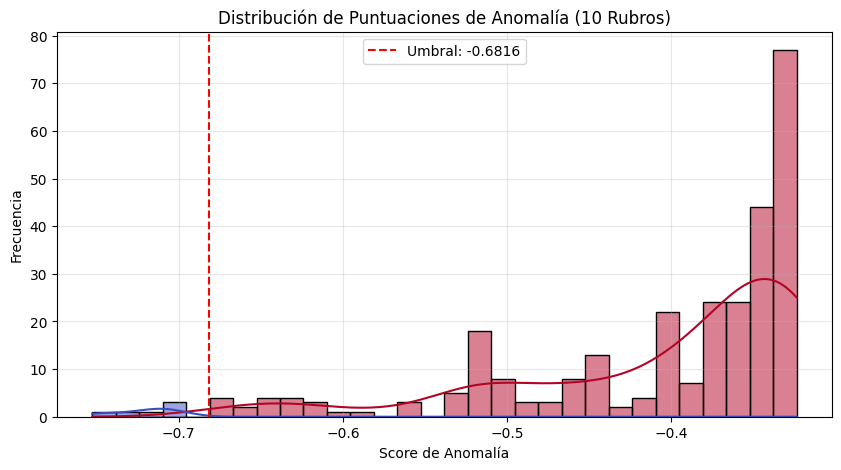


GRÁFICO DE DISPERSIÓN EN 3D


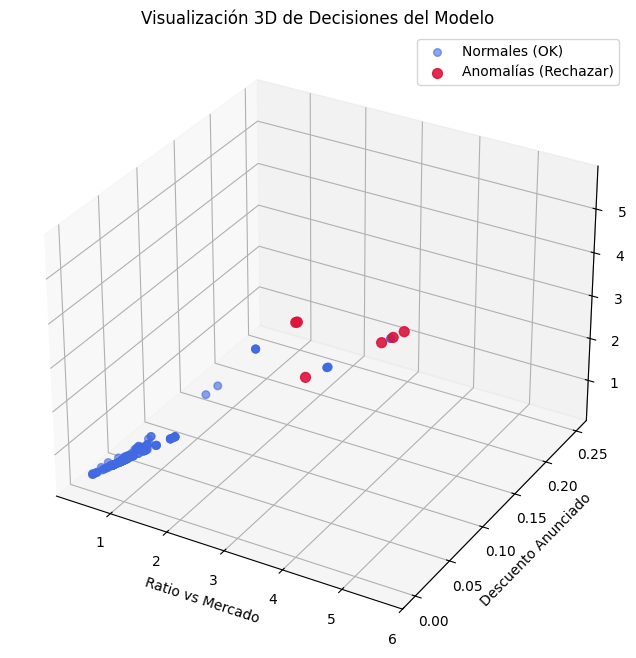

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. CÁLCULO DEL PUNTAJE DE DESEMPEÑO DEL MODELO (0 a 100) ---
total = len(df_train_10)
anomalias = (df_train_10['prediccion'] == -1).sum()

# Componente de Separación (Silhouette): mapea [-1, 1] a [0, 100]
sil_component = max(0, (sil_score + 1) / 2) * 100

# Componente de Calibración: penaliza desvíos respecto al 3% configurado
tasa_real = anomalias / total
tasa_objetivo = 0.02  # Mismo valor que 'contamination' en la Celda B
desvio = abs(tasa_real - tasa_objetivo)
calib_component = max(0, 1 - (desvio / tasa_objetivo)) * 100

# Ponderación final (70% Silueta, 30% Calibración)
performance_score = (0.70 * sil_component) + (0.30 * calib_component)

print("==================================================")
print(f"   PUNTAJE DE DESEMPEÑO DEL MODELO: {performance_score:.2f} / 100")
print("==================================================")
print(f"- Sub-score Separación (Silueta): {sil_component:.2f}/100")
print(f"- Sub-score Calibración: {calib_component:.2f}/100")
print(f"- Detalle: {anomalias} anomalías detectadas de {total} registros ({tasa_real:.2%})\n")

# --- 2. HISTOGRAMA DE SCORES ---
print("HISTOGRAMA DE SCORES")
plt.figure(figsize=(10, 5))
sns.histplot(data=df_train_10, x='anomaly_score', hue='prediccion', bins=30, kde=True, palette='coolwarm')
plt.axvline(x=modelo_detector_10.offset_, color='r', linestyle='--', label=f'Umbral: {modelo_detector_10.offset_:.4f}')
plt.title('Distribución de Puntuaciones de Anomalía (10 Rubros)')
plt.xlabel('Score de Anomalía')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- 3. GRÁFICO DE DISPERSIÓN EN 3D ---
print("\nGRÁFICO DE DISPERSIÓN EN 3D")
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

normales = df_train_10[df_train_10['prediccion'] == 1]
anomalas = df_train_10[df_train_10['prediccion'] == -1]

ax.scatter(normales['ratio_vs_mercado'], normales['descuento_anunciado'], normales['ratio_promo_vs_mercado'],
           c='royalblue', label='Normales (OK)', alpha=0.6, s=30)
ax.scatter(anomalas['ratio_vs_mercado'], anomalas['descuento_anunciado'], anomalas['ratio_promo_vs_mercado'],
           c='crimson', label='Anomalías (Rechazar)', alpha=0.9, s=50)

ax.set_xlabel('Ratio vs Mercado')
ax.set_ylabel('Descuento Anunciado')
ax.set_zlabel('Ratio Promo vs Mercado')
ax.set_title('Visualización 3D de Decisiones del Modelo')
plt.legend()
plt.show()

## La Fórmula del Score (0 a 100 puntos)

Usaremos un modelo estadístico de score ponderado que transforma los precios limpios en un puntaje de 0 a 100 puntos para saber qué supermercado gana en cada rubro, donde:


*   Score Precio Lista (50%): Mide qué tan barato es el precio regular frente al promedio del mercado (precio_mercado_medio / precio_lista_ref). Si está exactamente en el promedio del mercado, suma 35/50 puntos; si es un 15% más barato, llega al máximo de 50/50 puntos.

*   Score Precio Final con Promo (35%): Evalúa el precio efectivo que paga el cliente (precio_mercado_medio / precio_promo_ref). Premia al supermercado que logra el precio más bajo real, ya sea por lista baja o por descuento directo.

*   Score Agresividad de Ofertas (15%): Mide qué porcentaje de los productos de esa categoría tienen una promoción real activa (precio_promo_ref < precio_lista_ref). Diferencia a una cadena que mantiene precios bajos todos los días (como suele hacer Cooperativa Obrera o Día) de una que infla precios y hace descuentos agresivos.

In [16]:
import numpy as np

def calcular_score_rubro(precio_lista_ref, precio_promo_ref, precio_mercado_medio):
    # 1. Score Precio Lista (máx 50 pts; 35 pts si iguala la mediana del mercado por kg/L)
    ratio_lista = precio_mercado_medio / precio_lista_ref
    score_lista = np.clip(ratio_lista * 35, 0, 50)

    # 2. Score Precio Final con Promo (máx 35 pts; 25 pts si iguala la mediana del mercado)
    ratio_final = precio_mercado_medio / precio_promo_ref
    score_final = np.clip(ratio_final * 25, 0, 35)

    # 3. Score Agresividad de Ofertas (15 pts si la mediana con promo mejora el precio de lista)
    tiene_promo = 15 if precio_promo_ref < precio_lista_ref else 0

    return round(float(score_lista + score_final + tiene_promo), 2)

## Evaluación Heurística y Clasificación por Rangos

Al trabajar con un modelo de aprendizaje no supervisado (`IsolationForest`) que no cuenta con etiquetas previas, complementamos las métricas estadísticas con un sistema de **reglas heurísticas por umbrales** sobre el score competitivo (0 a 100 puntos) para validar e interpretar comercialmente cada registro:

*   **Rango 0 (Anomalía IA):** Registros marcados como atípicos (`prediccion == -1`) por presentar precios fuera de escala o errores de unitización frente al mercado.
*   **Rango 1 (70 a 100 pts - Ofertas Agresivas):** Productos con precios significativamente más bajos que la mediana del mercado o con promociones activas fuertes.
*   **Rango 2 (55 a 69.9 pts - Precios Equilibrados):** Productos cuyos precios regulares y promocionales se mantienen en línea con el promedio del mercado.
*   **Rango 3 (0 a 54.9 pts - Sobreprecios):** Productos con valores regularmente por encima de la media del mercado sin descuentos compensatorios.

In [ ]:
# --- EVALUACIÓN HEURÍSTICA POR RANGOS DE SCORE Y DETECCIÓN DE ANOMALÍAS ---

# 1. Calculamos el score competitivo (0 a 100) sobre todo el dataset de entrenamiento
df_train_10['score_competitividad'] = df_train_10.apply(
    lambda row: calcular_score_rubro(
        row['precio_lista_ref'],
        row['precio_promo_ref'],
        row['precio_mercado_medio']
    ),
    axis=1
)

# 2. Función de reglas heurísticas (umbrales definidos para interpretación de negocio)
def clasificar_rango_heuristico(prediccion, score):
    if prediccion == -1:
        return "Rango 0 (Anomalía IA): Dato atípico / Error de unitización o scraping"
    elif score >= 70:
        return "Rango 1 (70 - 100 pts): Ofertas agresivas / Alta competitividad"
    elif score >= 55:
        return "Rango 2 (55 - 69.9 pts): Precios equilibrados / En línea con el mercado"
    else:
        return "Rango 3 (0 - 54.9 pts): Sobreprecios / Fuera de competencia"

# 3. Bucle con condicionales if para clasificar e imprimir resultados preliminares
conteo_rangos = {
    "Rango 0 (Anomalía IA): Dato atípico / Error de unitización o scraping": 0,
    "Rango 1 (70 - 100 pts): Ofertas agresivas / Alta competitividad": 0,
    "Rango 2 (55 - 69.9 pts): Precios equilibrados / En línea con el mercado": 0,
    "Rango 3 (0 - 54.9 pts): Sobreprecios / Fuera de competencia": 0
}

clasificaciones = []
for idx, row in df_train_10.iterrows():
    pred = row['prediccion']
    sc = row['score_competitividad']

    if pred == -1:
        etiqueta = "Rango 0 (Anomalía IA): Dato atípico / Error de unitización o scraping"
    elif sc >= 70:
        etiqueta = "Rango 1 (70 - 100 pts): Ofertas agresivas / Alta competitividad"
    elif sc >= 55:
        etiqueta = "Rango 2 (55 - 69.9 pts): Precios equilibrados / En línea con el mercado"
    else:
        etiqueta = "Rango 3 (0 - 54.9 pts): Sobreprecios / Fuera de competencia"

    clasificaciones.append(etiqueta)
    conteo_rangos[etiqueta] += 1

df_train_10['rango_heuristico'] = clasificaciones

# 4. Imprimimos el resumen preliminar de los rangos
print("=========================================================================")
print("   RESULTADOS PRELIMINARES DE CLASIFICACIÓN HEURÍSTICA (290 REGISTROS)")
print("=========================================================================")
total_reg = len(df_train_10)
for rango, cantidad in conteo_rangos.items():
    porcentaje = (cantidad / total_reg) * 100
    print(f"- {rango}: {cantidad} registros ({porcentaje:.2f}%)")

print("\n--- MUESTRA DE EJEMPLOS POR RANGO ---")
display(df_train_10[['fecha', 'supermercado', 'tipo_producto', 'precio_lista_ref', 'precio_promo_ref', 'precio_mercado_medio', 'score_competitividad', 'rango_heuristico']].head(15))

   RESULTADOS PRELIMINARES DE CLASIFICACIÓN HEURÍSTICA (290 REGISTROS)
- Rango 0 (Anomalía IA): Dato atípico / Error de unitización o scraping: 6 registros (2.07%)
- Rango 1 (70 - 100 pts): Ofertas agresivas / Alta competitividad: 88 registros (30.34%)
- Rango 2 (55 - 69.9 pts): Precios equilibrados / En línea con el mercado: 150 registros (51.72%)
- Rango 3 (0 - 54.9 pts): Sobreprecios / Fuera de competencia: 46 registros (15.86%)

--- MUESTRA DE EJEMPLOS POR RANGO ---


,fecha,supermercado,tipo_producto,precio_lista_ref,precio_promo_ref,precio_mercado_medio,score_competitividad,rango_heuristico
0,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Aceite,5000.00,5000.00,4752.670,57.03,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
1,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Arroz,2510.00,2510.00,2470.000,59.04,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
2,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Azucar,10405.27,10405.27,7619.050,43.93,Rango 3 (0 - 54.9 pts): Sobreprecios / Fuera d...
3,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Detergente,9036.63,9036.63,8908.315,59.15,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
4,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Fideos,6300.00,6300.00,5980.000,56.95,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
5,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Gaseosa,2711.11,2711.11,2746.670,60.79,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
6,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Leche,2650.00,2650.00,2650.000,60.00,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
7,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Queso,25990.00,25990.00,23490.000,54.23,Rango 3 (0 - 54.9 pts): Sobreprecios / Fuera d...
8,2026-11-05,COTO CENTRO INTEGRAL DE COMERCIALIZACION S.A.,Yerba,5460.00,5460.00,5400.000,59.34,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
9,2026-11-05,Cencosud S.A.,Aceite,5000.00,5000.00,4752.670,57.03,Rango 2 (55 - 69.9 pts): Precios equilibrados ...
